# 05 — Proposed Algorithm Development (`DIFW-KNN` pada `Training / Development Data`)

**Modul Inti:** [`src/mixed_type_distance.py`](../src/mixed_type_distance.py), [`src/triplet_learning.py`](../src/triplet_learning.py), [`src/feature_weight_optimizer.py`](../src/feature_weight_optimizer.py), [`src/cost_sensitive_decision.py`](../src/cost_sensitive_decision.py), [`src/difw_knn.py`](../src/difw_knn.py)  
**Skrip CLI:** [`src/05_proposed_difw_knn.py`](../src/05_proposed_difw_knn.py)  
**Laporan:** [`Laporan_Proposed_DIFW_KNN.md`](../Laporan_Proposed_DIFW_KNN.md)

Notebook ini mengimplementasikan dan memvalidasi **6 sub-komponen di dalam kotak hijau `Proposed Algorithm Development`** pada *flowchart* secara berurutan di atas **`Training / Development Data` (`36.168` baris)** (`Hold-out Test Data` tetap dikunci hingga Tahap 07):
1. **Mixed-Type Distance:** Normalisasi interkuantil terklip $d_j(x,z) = \min(1, |x_j - z_j|/(Q_{95,j}-Q_{05,j}))$ untuk numerik & *mismatch* untuk kategorikal (dipercepat dengan matriks *OpenBLAS*).
2. **Balanced Triplet Sampling:** Penarikan triplet seimbang `50:50` dengan strategi *Hybrid Global + Local-Context* agar klaster kampanye multimodal tetap koheren.
3. **Triplet Margin Loss:** Verifikasi gradien analitik terhadap *central finite-difference* ($< 10^{-7}$).
4. **Supervised Feature Weight Learning:** Optimasi *Projected Gradient Descent* pada simpleks probabilitas ($w_j \ge 0, \sum w_j = 1$) & uji stabilitas 5 *random seed*.
5. **Weighted KNN & Local Probability:** Estimasi probabilitas lokal $\hat{P}(\text{yes}|x)$ berbasis peluruhan jarak $\alpha_i = (D_w(x, x_i) + \epsilon)^{-q}$.
6. **Cost-Sensitive Decision Rule:** Ambang keputusan Bayes $\tau^* = \frac{C_{\text{FP}}}{C_{\text{FP}} + C_{\text{FN}}}$ dan analisis *trade-off* rasio biaya.

## 1. Sub-Tahap 1–4: Validasi Komponen Jarak, Triplet Sampling, Gradient Check, & Pembelajaran Bobot Fitur

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

train_df = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'train_split.csv')
out_dir = PROJECT_ROOT / 'outputs' / 'proposed_difw_knn'

print(f'Training/Development rows loaded: {len(train_df):,} (Hold-out Test locked)')
checks_df = pd.read_csv(out_dir / 'component_validation_checks.csv')
weights_df = pd.read_csv(out_dir / 'dev_learned_feature_weights.csv')
stability_df = pd.read_csv(out_dir / 'dev_weight_seed_stability.csv')

display(checks_df)
display(weights_df.round(5))
display(stability_df.round(5))

Training/Development rows loaded: 36,168 (Hold-out Test locked)


,id,sub_stage,check,value,status
0,1,Mixed-Type Distance,"Self-distance d_j(x, x) = 0",max_diag=0.0e+00,PASS
1,2,Mixed-Type Distance,"Simetri d_j(x, z) = d_j(z, x)",max_diff=0.0e+00,PASS
2,3,Mixed-Type Distance,"Rentang d_j(x, z) dalam [0, 1]","[0.0000, 1.0000]",PASS
3,4,Mixed-Type Distance,Ekuivalensi OpenBLAS vs exact loop,max_diff=2.22e-16,PASS
4,5,Balanced Triplet Sampling,Proporsi anchor 50:50 & label valid,"pos_ratio=0.500, valid=True",PASS
5,6,Triplet Margin Loss,Gradient check analitik vs numerik (<1e-7),max_abs_err=3.96e-11,PASS
6,7,Feature Weight Learning,"Kendala simpleks (w_j >= 0, sum = 1)","min=0.00000, sum=1.000000000000",PASS
7,8,Feature Weight Learning,Penurunan Triplet Margin Loss,0.28153 -> 0.22732,PASS
8,9,Feature Weight Learning,Stabilitas bobot lintas 5 random seed,"Spearman=0.9906, Cosine=0.9993",PASS


,feature,weight,uniform_weight,relative_importance,weight_pct
0,month,0.30789,0.0625,4.92621,30.78879
1,poutcome,0.10459,0.0625,1.67342,10.45887
2,day,0.10018,0.0625,1.60295,10.01845
3,previously_contacted,0.09002,0.0625,1.44033,9.00208
4,age,0.08684,0.0625,1.38937,8.68358
5,campaign,0.07360,0.0625,1.17756,7.35977
6,pdays_recency,0.05710,0.0625,0.91361,5.71009
7,balance,0.05295,0.0625,0.84721,5.29506
8,contact,0.05236,0.0625,0.83771,5.23568
9,previous,0.02994,0.0625,0.47907,2.99421


,feature,weight_mean,weight_std,weight_min,weight_max
0,month,0.30747,0.00178,0.30436,0.30968
1,poutcome,0.10303,0.00289,0.10015,0.10784
2,day,0.09661,0.00260,0.09366,0.10018
3,age,0.09098,0.00306,0.08684,0.09436
4,previously_contacted,0.09009,0.00222,0.08734,0.09324
5,campaign,0.06995,0.00293,0.06672,0.07360
6,pdays_recency,0.05816,0.00221,0.05564,0.06110
7,balance,0.05731,0.00326,0.05295,0.06257
8,contact,0.05054,0.00179,0.04765,0.05236
9,housing,0.02921,0.00130,0.02738,0.03079


## 2. Sub-Tahap 5–6: Evaluasi Kontribusi Komponen (`E0_dev` $\rightarrow$ `E5_dev`) & Aturan Keputusan Sensitif Biaya pada 5-Fold Development

In [2]:
prog_df = pd.read_csv(out_dir / 'dev_5fold_component_progression.csv')
cost_df = pd.read_csv(out_dir / 'dev_cost_ratio_grid.csv')

prog_cols = ['model_id', 'model_label', 'accuracy_mean', 'precision_yes_mean', 'recall_yes_mean', 'f1_yes_mean', 'pr_auc_mean', 'roc_auc_mean', 'mcc_mean', 'g_mean_mean']
display(prog_df[prog_cols].round(4))

cost_cols = ['c_fn', 'threshold', 'accuracy', 'precision_yes', 'recall_yes', 'f1_yes', 'mcc', 'g_mean', 'mean_cost', 'cost_reduction_pct']
display(cost_df[cost_cols].round(4))

,model_id,model_label,accuracy_mean,precision_yes_mean,recall_yes_mean,f1_yes_mean,pr_auc_mean,roc_auc_mean,mcc_mean,g_mean_mean
0,E0_dev,"Standard Euclidean KNN (k=5, uniform, tau=0.50)",0.8863,0.5364,0.2026,0.2938,0.2823,0.6896,0.2804,0.4444
1,E2_dev,"Mixed-Type KNN (k=31, uniform, tau=0.50)",0.8923,0.6549,0.1676,0.2668,0.3917,0.7520,0.2940,0.4068
2,E3_dev,"Feature-Weighted KNN (k=31, triplet, tau=0.50)",0.8941,0.6224,0.2408,0.3470,0.4184,0.7706,0.3422,0.4858
3,E4_dev,"Cost-Sensitive Mixed KNN (k=31, uniform, tau=0.1667)",0.8332,0.3516,0.5041,0.4142,0.3917,0.7520,0.3277,0.6648
4,E5_dev,"Proposed DIFW-KNN (k=31, triplet + tau=0.1667)",0.8466,0.3902,0.5521,0.4571,0.4184,0.7706,0.3785,0.6992


,c_fn,threshold,accuracy,precision_yes,recall_yes,f1_yes,mcc,g_mean,mean_cost,cost_reduction_pct
0,1.00,0.5000,0.8940,0.6217,0.2408,0.3472,0.3422,0.4860,0.1060,0.0000
1,2.00,0.3333,0.8832,0.5007,0.4035,0.4469,0.3852,0.6180,0.1866,4.1738
2,3.00,0.2500,0.8745,0.4646,0.4758,0.4701,0.3990,0.6642,0.2481,12.5000
3,4.00,0.2000,0.8626,0.4274,0.5138,0.4667,0.3908,0.6834,0.3080,17.2854
4,5.00,0.1667,0.8466,0.3901,0.5521,0.4572,0.3785,0.6993,0.3629,21.3010
5,7.55,0.1170,0.7841,0.3001,0.6346,0.4075,0.3267,0.7143,0.4958,27.8936
6,10.00,0.0909,0.7187,0.2488,0.6953,0.3664,0.2858,0.7085,0.6020,33.4942


## 3. Visualisasi Konvergensi Loss, Bobot Fitur, Progresi Komponen, dan Sensitivitas Biaya

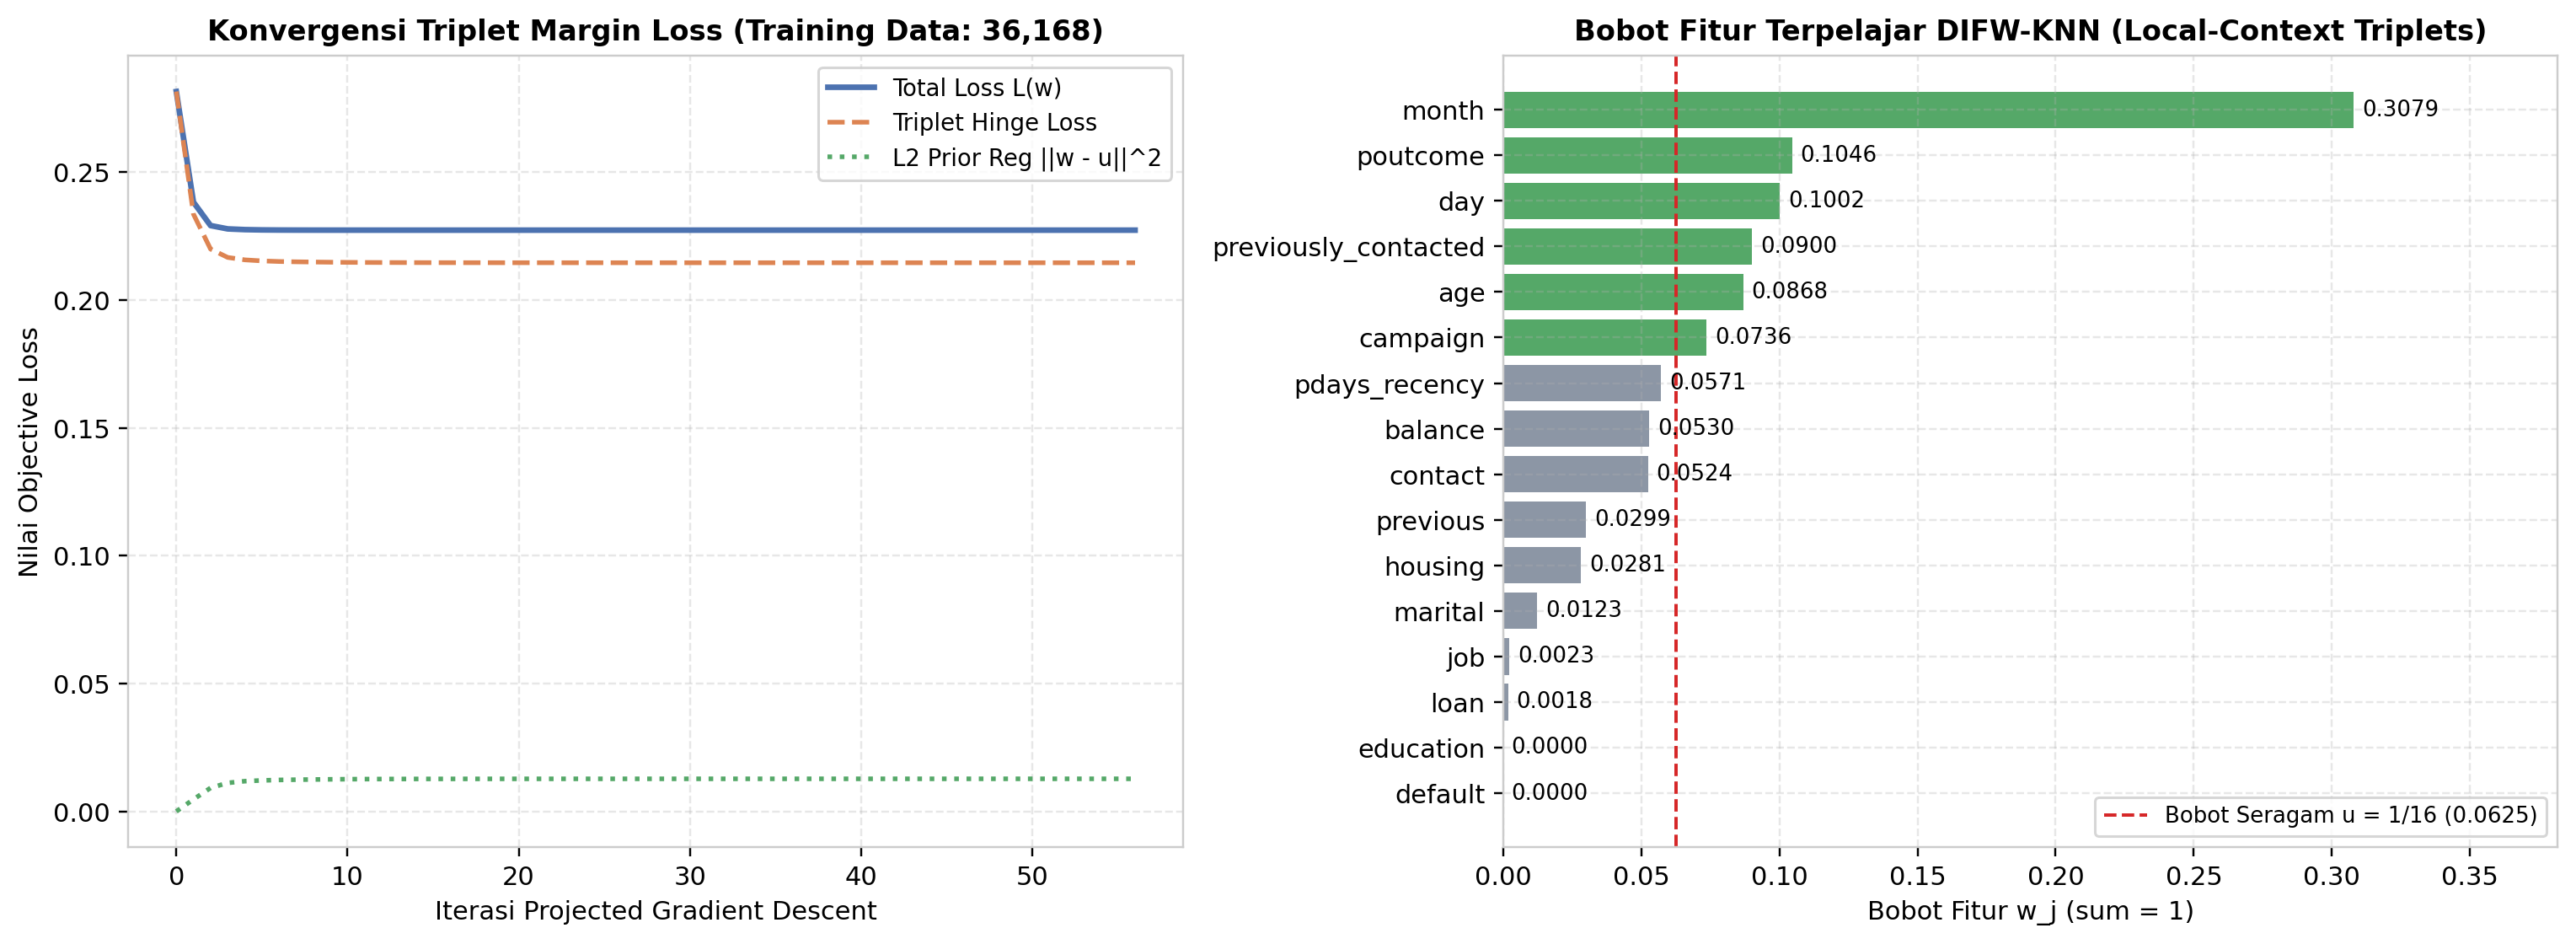

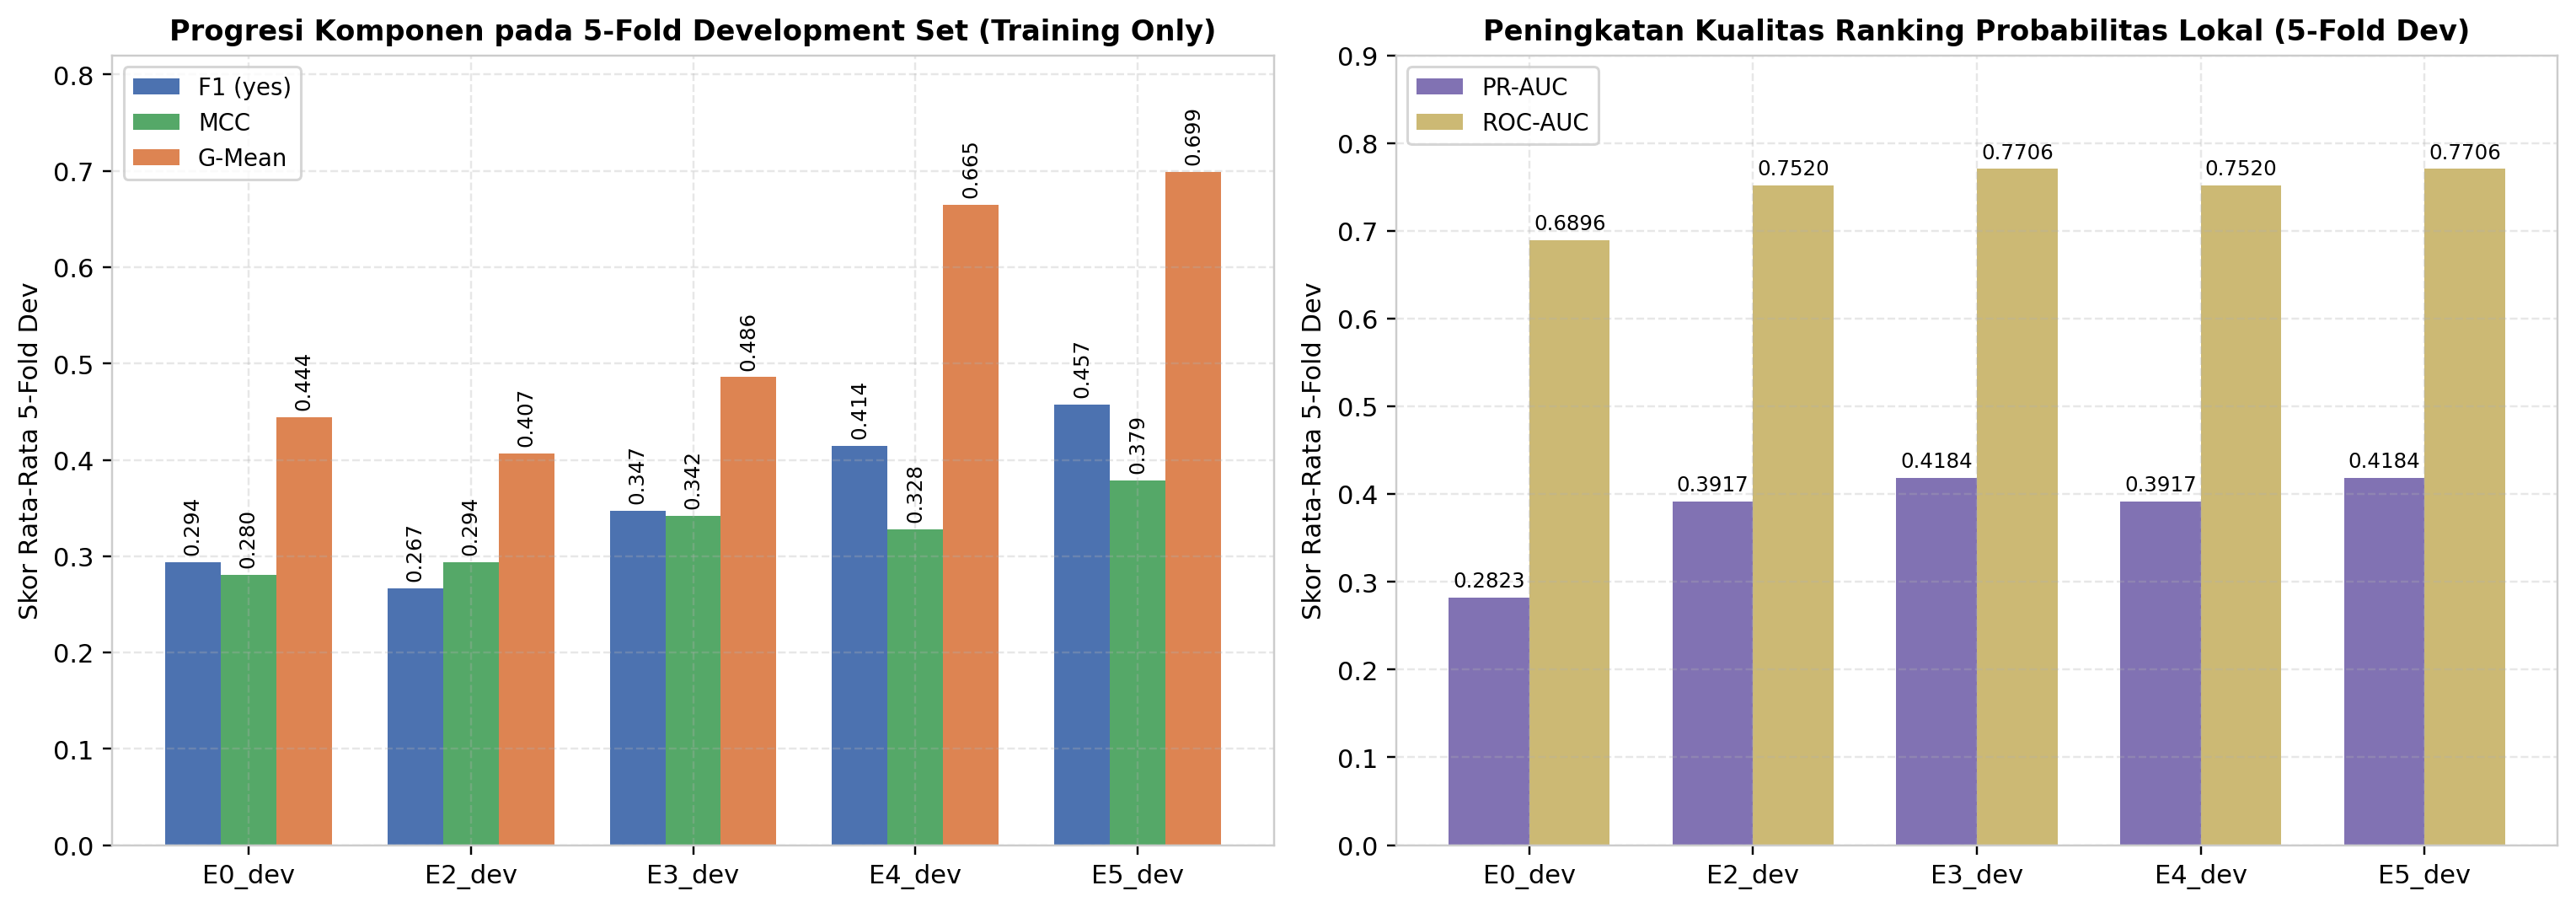

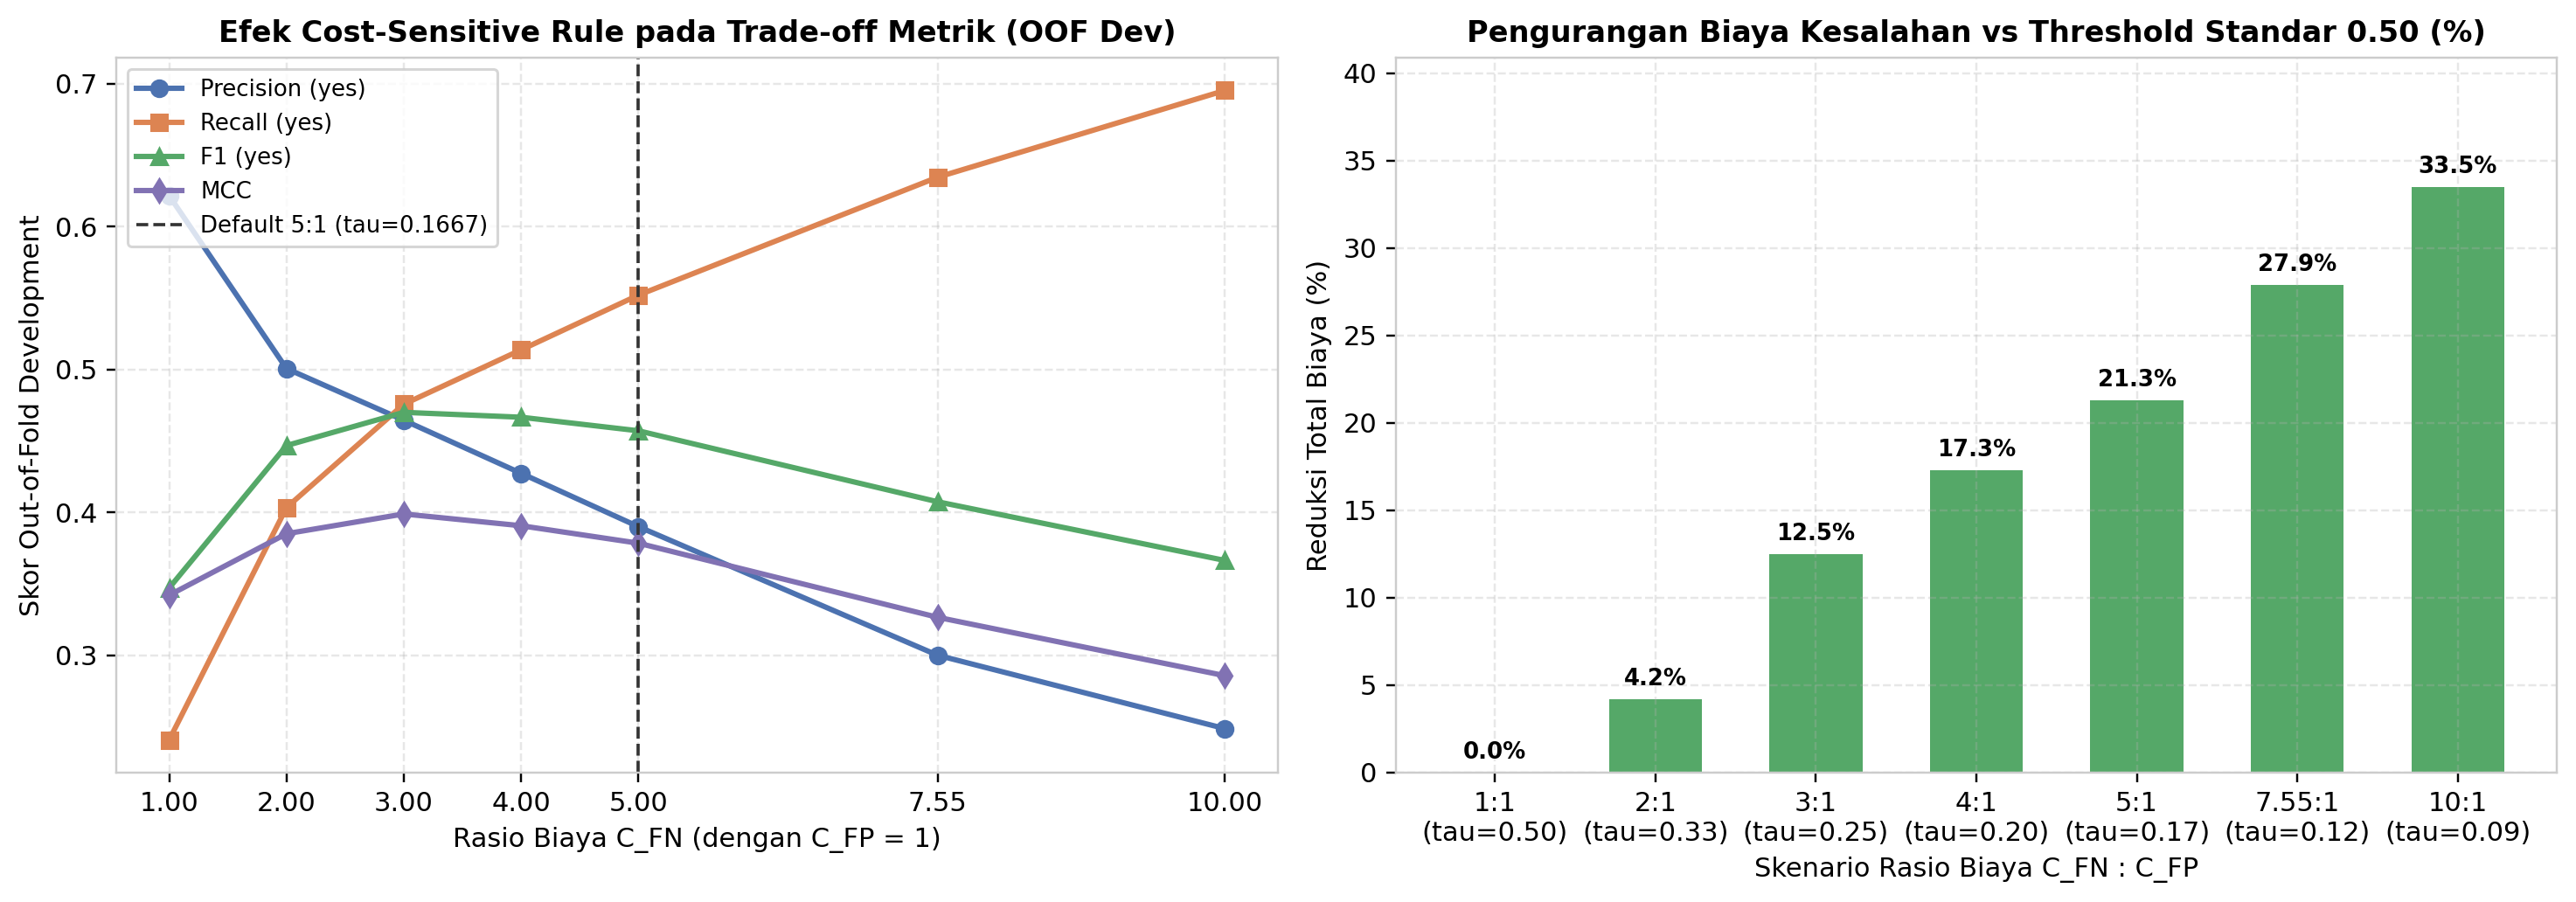

In [3]:
fig_dir = out_dir / 'figures'
for fname in [
    '01_triplet_loss_and_feature_weights.png',
    '02_dev_component_progression.png',
    '03_cost_sensitive_rule_behavior.png',
]:
    display(Image(fig_dir / fname))